In [1]:
# a master script that performs the deglitching of the data at the HOOF station which is one of the planned vertices
# for hosting Einstein Telescope
import numpy as np
import scipy.io as sio
from scipy.io import savemat,loadmat
import scipy.signal as sp
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import math as mt
import os.path as op
import obspy
import statistics as st
from obspy.core import read
from obspy.core.trace import Trace
from obspy.core.stream import Stream
from obspy import UTCDateTime
from obspy import read_inventory
from scipy.fft import fft, fftfreq
from scipy.spatial.distance import cdist
from scipy.signal import periodogram
from scipy import signal
from scipy.optimize import least_squares
from scipy.ndimage import uniform_filter1d, median_filter
from scipy.optimize import minimize
import pickle
import datetime
import pywt
from fractions import Fraction
import pywt
from scipy.signal import resample_poly
from scipy.signal import fftconvolve
from scipy.linalg import solve
from scipy.linalg import lstsq
from obspy.clients.filesystem.sds import Client
from obspy.clients.fdsn import Client as ClientFDSN
from modules import oldDeGlitch, deGlitch, procStream, psdEst

In [2]:
# specify the path for the seismic data and station response files
stnAll = ['HOOF']
locCodeAll = ['01',]
netCodeAll = ['NL']
compCodeAll = [['BH1','BH2','BHZ'],]

archiveAll = []

for i in range(len(stnAll)):
    rootTemp = '/dcache/etseis/et/EMR/Data'
    archiveTemp = Client(rootTemp)
    archiveAll.append(archiveTemp)

# assign the response files
invAll = []

for i,stnName in enumerate(stnAll):
    if(stnAll[i]=='LALA'):
        respPathTemp = f"/data/gravwav/koley/ETAnalysis2026/StationXML/NL.{stnAll[i]}.xml"
    else:        
        respPathTemp = f"/dcache/etseis/et/EMR/Stations/Stations/NL.{stnAll[i]}.xml"
    
    invTemp = read_inventory(respPathTemp)
    invAll.append(invTemp)


/data/gravwav/koley/my_venv/lib/python3.10/site-packages/obspy/io/stationxml/core.py:91: UserWarning: The StationXML file has version 1.2, ObsPy can read versions (1.0, 1.1). Proceed with caution.
  warnings.warn("The StationXML file has version %s, ObsPy can "


In [3]:
"""
# download the HOOF xml from FDSN, seems to be ambiguous, as per Valentin
clientFDSN = ClientFDSN("KNMI")

# 2. Define your time window
# Format can be "YYYY-MM-DD" or "YYYY-MM-DDTHH:MM:SS"
t1 = UTCDateTime("2026-07-10T00:00:00")
t2 = UTCDateTime("2026-10-13T23:59:59")

# 3. Query the metadata active within this window
inventory = clientFDSN.get_stations(
    network="NL", 
    station="TEUV", 
    starttime=t1,
    endtime=t2,
    level="response"
)

# 4. Save to a file
inventory.write("/data/gravwav/koley/ETAnalysis2026/StationXML/NL.TEUV.xml", format="StationXML")
"""

'\n# download the HOOF xml from FDSN, seems to be ambiguity\nclientFDSN = ClientFDSN("KNMI")\n\n# 2. Define your time window\n# Format can be "YYYY-MM-DD" or "YYYY-MM-DDTHH:MM:SS"\nt1 = UTCDateTime("2026-07-10T00:00:00")\nt2 = UTCDateTime("2026-10-13T23:59:59")\n\n# 3. Query the metadata active within this window\ninventory = clientFDSN.get_stations(\n    network="NL", \n    station="TEUV", \n    starttime=t1,\n    endtime=t2,\n    level="response"\n)\n\n# 4. Save to a file\ninventory.write("/data/gravwav/koley/ETAnalysis2026/StationXML/NL.TEUV.xml", format="StationXML")\n'

In [4]:
# specify the start date and end date of the analysis
# Analyzing January, 2022 - December, 2024

def getDate(dateSt,yearSt):
    dayNowSt = int(dateSt[0])
    yearNowSt = yearSt[0]
    A = datetime.datetime(yearNowSt,1,1)+datetime.timedelta(days=dayNowSt -1)
    monthNowSt = A.month
    monthDaySt = A.day
    monthYearSt = A.year
    dateStUse = UTCDateTime(monthYearSt,monthNowSt,monthDaySt)
    return dateStUse

dateStart = np.array([225])# previously 202
yearStart = np.array([2026])

# do the same for end time
# ideally dateStart +1, because later you look hour by hour for this day
dateEnd = np.array([226])
yearEnd = np.array([2026])

dateStUse = getDate(dateStart,yearStart)
dateEndUse = getDate(dateEnd, yearEnd)

print(dateStUse)
print(dateEndUse)


2026-08-13T00:00:00.000000Z
2026-08-14T00:00:00.000000Z


In [5]:
# specify the data analysis parameters, like the extraction lengths, buffer, psdlen, psdoverlap
extractLen = 3600 # ideally want to extract data every hour, units in seconds
dataBuffA = 5*extractLen/100 # when removing instrument response a 5 percent taper is applied,l 2.5% on each side
dataBuffB = 60 # units in s, since we do psd every 120 s with ioverlap of 60 s
dataBuffTotStart = dataBuffA + dataBuffB
dataBuffTotEnd = dataBuffA # the end only takes care of tapering, since the next window starts with data from 60 s before
preFilt = [0.01,0.05,15,18] # prefiltering while instrument response removal
psdLen = 120 # units in s
psdOv = 60 # units in s
psdWinHour = (extractLen+dataBuffB-psdOv)//(psdLen-psdOv)
fSamp = 40
print('Total PSDs per hour = '+ str(psdWinHour))

Total PSDs per hour = 60


In [6]:
# create list of station names, component, loc code, slightly different from here, possible to avoid
stnList = []; locList = []; compList=[]; netList =[]
for stnNo in range(0,len(stnAll)):
    for i in range(0,3):
        stnList.append(stnAll[stnNo])
        locList.append(locCodeAll[stnNo])
        compList.append(compCodeAll[stnNo][i])
        netList.append(netCodeAll[stnNo])

print(stnList);print(compList);print(locList);print(netList)

['HOOF', 'HOOF', 'HOOF']
['BH1', 'BH2', 'BHZ']
['01', '01', '01']
['NL', 'NL', 'NL']


In [7]:
deGlitchStns = ['HOOF']
# assume you want to detect glitch intervals in the underground stations
# find the indices
deGlitchInd = []
for i in range(len(deGlitchStns)):
    tempInd = [j for j, (a, b) in enumerate(zip(stnList, locList)) if a == deGlitchStns[i] and b == '01']
    deGlitchInd.append(tempInd)

print(deGlitchInd)

[[0, 1, 2]]


In [8]:
plt.rcParams.update({
    'figure.titlesize': 18,     # Overall figure suptitle size
    'axes.titlesize': 16,       # Subplot title size
    'axes.labelsize': 16,       # X and Y axis labels (e.g. "Frequency (Hz)")
    'xtick.labelsize': 16,      # X-axis tick numbers/values
    'ytick.labelsize': 16,      # Y-axis tick numbers/values
    'legend.fontsize': 14,      # Legend text size
})

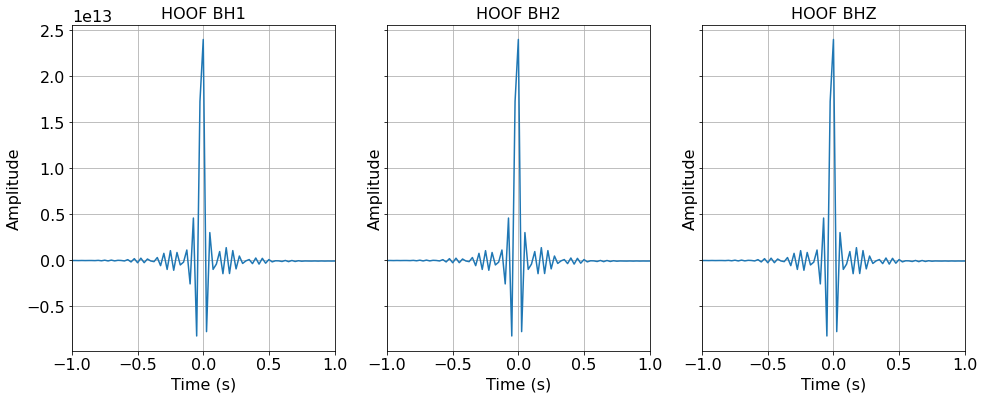

In [9]:
stNo = 0
dateStUse = dateStUse + 3600*1 # look hour by hour for the day, between 0 - 23
dateLoopStart = dateStUse#
fig,ax = plt.subplots(1,3,figsize=(16,6),sharey=True)
for i in range(0,3):
    templateDisp, tTemplateDisp,scaleTemplateDisp = deGlitch.makeDispStepTemplate(inventory=invAll[stNo//3],network=netList[stNo+i],
                                                   station=stnList[stNo+i],location=locList[stNo+i],
                                                   channel=compList[stNo+i],fs=fSamp,responseTime=dateLoopStart,
                                                       templateSec=200.0,preSec=30.0,simulationSec=600.0,normalize=False)
    ax[i].plot(tTemplateDisp,templateDisp)
    ax[i].set_ylabel('Amplitude')
    ax[i].set_xlabel('Time (s)')
    ax[i].set_xlim(-1,1)
    ax[i].set_title(f"{stnList[stNo+i]} {compList[stNo+i]}")
    ax[i].grid()

In [10]:
dispResolution = deGlitch.getDispTemplateResolution(
    templateDisp,
    tTemplateDisp,
    corrThreshold=0.5
)
print("DISP resolution =",dispResolution["samples"],"samples =",dispResolution["seconds"],"s")

DISP resolution = 1 samples = 0.025000000000005684 s


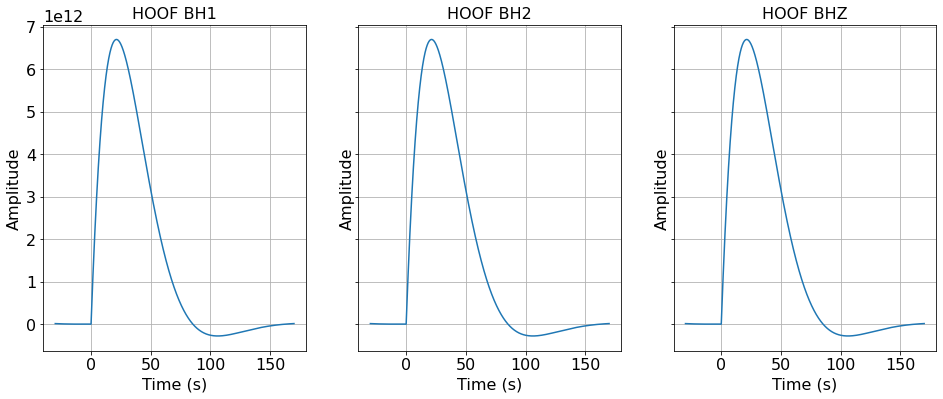

In [11]:
stNo = 0
dateStUse = dateStUse + 3600*1 # look hour by hour for the day, between 0 - 23
dateLoopStart = dateStUse#
fig,ax = plt.subplots(1,3,figsize=(16,6),sharey=True)
for i in range(0,3):
    template, tTemplate,scaleTemplate = deGlitch.makeAccelerationStepTemplate(inventory=invAll[stNo//3],network=netList[stNo+i],
                                                   station=stnList[stNo+i],location=locList[stNo+i],
                                                   channel=compList[stNo+i],fs=fSamp,responseTime=dateLoopStart,
                                                       templateSec=200.0,preSec=30.0,simulationSec=600.0,normalize=False)
    ax[i].plot(tTemplate,template)
    ax[i].set_ylabel('Amplitude')
    ax[i].set_xlabel('Time (s)')
    #ax[i].set_xlim(0,180)
    ax[i].set_title(f"{stnList[stNo+i]} {compList[stNo+i]}")
    ax[i].grid()

In [35]:
# HOURLY PROCESSING: G1 windows -> G2 peaks -> LF physical fit -> G2 SWT -> PSDs
# Paste into ONE notebook cell after the existing helper functions/imports are loaded.
# NO new function definitions, NO old G1 waveform reconstruction, NO G1 fit fallback.
# Requires cleanGlitchesG2SWT() to output peak_times_hour_by_stream.
# One-hour validation first: this is not yet a tested unattended production release.
# ------------------------------------------------------------
# RUN SETTINGS (retain the previously selected test hour)
# ------------------------------------------------------------
nHours = 1
startHourOffset = 12  # Change to 0 for the first hour of dateStart

coincidenceSec = 0.5
sharedFitMarginSec = 35.0
sharedFitLowpass = 0.35
sharedFitFs = 5.0
sharedDerivativeWeightSec = 4.0  # latest supplied cell; tune only after validation
sharedRidgeFraction = 1e-3
sharedMaxEvents = 1000

# Baseline-only -> physical G2 model weighted variance reduction threshold.
# 0.0 requires only an improvement; a stricter threshold needs validation.
minSharedWeightedVR = 0.0

# ------------------------------------------------------------
# INITIALIZATION
# ------------------------------------------------------------
dateStUse = getDate(dateStart, yearStart) + 3600*startHourOffset
dateLoopStart = dateStUse
dateEndUse = dateStUse + nHours*extractLen
missingAll = []

histkw = dict(nChannels=len(stnList), psdMin=1e-30, psdMax=1e-8,nPsdBins=220, freqMin=0.05, freqMax=20.0)
histAll, psdEdges, psdCenters, freqHist, freqEdges = (
    psdEst.initializePSHistograms(df=1.0/psdLen, **histkw))
histAllDeGlitch, _, _, _, _ = (psdEst.initializePSHistograms(df=1.0/psdLen, **histkw))

histAllDeGlitchRec, _, _, _, _ = (psdEst.initializePSHistograms(df=1.0/psdLen, **histkw))

histAllMB, psdEdgesMB, psdCentersMB, freqHistMB, freqEdgesMB = (psdEst.initializePSHistograms(df=1.0/900.0, **histkw))

histAllMBDeGlitch, _, _, _, _ = (psdEst.initializePSHistograms(df=1.0/900.0, **histkw))

histAllMBDeGlitchRec, _, _, _, _ = (psdEst.initializePSHistograms(df=1.0/900.0, **histkw))

totEventCountPerHourAll = {st: [] for st in deGlitchStns}
dataLossPerHourAll = {st: [] for st in deGlitchStns}
nCleanMBAll = []
nClean120All = []
productionFitLog = []

while dateLoopStart < dateEndUse:
    hourStartThis = dateLoopStart
    dateReadStart = hourStartThis - dataBuffTotStart
    dateReadEnd = hourStartThis + extractLen + dataBuffTotEnd

    # The SWT analysis grid is [hourStart-dataBuffB, hourStart+extractLen].
    # Therefore G2 onset candidates cannot be earlier/later than this range.
    # The physical fitting routine itself expands this interval by
    # sharedFitMarginSec and clips to actual raw trace coverage.
    g2PeakTimeRange = (-float(dataBuffB), float(extractLen))

    print('\nHour:', hourStartThis)
    print('  raw read:       ', dateReadStart, 'to', dateReadEnd)
    print('  G2 onset range: ', g2PeakTimeRange, 'seconds from hour start')
    if (dataBuffTotStart < dataBuffB + sharedFitMarginSec or dataBuffTotEnd < sharedFitMarginSec):
        print('  NOTE: Fit margin extends beyond read buffer; fit will be clipped.')

    # 1. Read original, full-buffer RAW streams.
    streamAll = procStream.loadStreams(archiveAll, invAll, stnList, stnAll, locList, compList,
                                         netList, dateReadStart, dateReadEnd)

    # 2. G1 VARIANCE-PURSUIT DETECTION: broad windows ONLY.
    # Do not call applyPhysicsG1Reconstruction() or constrained L1.
    physicsG1All = []
    eventsPassHorAll = []
    rawBHHorFlag = []
    for dNo, stationNow in enumerate(deGlitchStns):
        ci = deGlitchInd[dNo]
        horizontalIndices = [ci[1]] if stationNow == 'BSDL' else [ci[0], ci[1]]
        g1Now = deGlitch.detectPhysicsG1HorizontalWindows(streamAll, horizontalIndices, template, tTemplate,
                                                 hourStart=hourStartThis, extractLen=extractLen,
                                                 overlapBuffer=dataBuffB, lowpass=0.5,
                                                 maxEvents=40, shortlistSize=20,
                                                 highConfidenceVR=0.8, deltaVRThreshold=1e-3,
                                                 preSec=60.0, postSec=180.0)
        physicsG1All.append(g1Now)
        eventsPassHorAll.append(g1Now['intervals'])
        rawBHHorFlag.append(g1Now['has_data'])

    # 3. Response-corrected acceleration only for G2 interval detection
    # and the original-data PSD products.
    processedStream = procStream.prepareStream(streamAll, invAll, hourStartThis, extractLen,
                                                 dataBuffB=dataBuffB, output='ACC', preFilt=preFilt)

    # 4. INDEPENDENT BH1/BH2/BHZ G2 windows (union per station).
    refinedEventsHorAll = []  # Retain the original downstream variable name.
    for dNo, stationNow in enumerate(deGlitchStns):
        ci = deGlitchInd[dNo]
        params = dict(thresholdHigh=None, thresholdLow=None,thresholdHighFactor=8.0, thresholdLowFactor=2.0,
                      quietSec=1.0, padSec=1.0, shortSec=0.1,backgroundSec=20.0, sigmaFloorFactor=0.1,
                      returnDiagnostics=False)
        if stationNow == 'BSDL':
            intervals = oldDeGlitch.refineGlitchesDeconvolvedBSDLNew(processedStream, eventsPassHorAll[dNo],
                                                                      indH1=ci[1], indV=ci[2], **params)
        else:
            intervals = oldDeGlitch.refineGlitchesDeconvolvedNew(processedStream, eventsPassHorAll[dNo],
                                                                  indH1=ci[0], indH2=ci[1], indV=ci[2], **params)
        intervals = [] if intervals is None else intervals
        
        refinedEventsHorAll.append(intervals)

        if not rawBHHorFlag[dNo]:
            totEventCountPerHourAll[stationNow].append(None)
            dataLossPerHourAll[stationNow].append(None)
        else:
            totEventCountPerHourAll[stationNow].append(len(intervals))
            fsIntervals = next((float(processedStream[j][0].stats.sampling_rate)
                                for j in ci if processedStream[j] is not None
                                and len(processedStream[j]) == 1), float(fSamp))
            dataLossPerHourAll[stationNow].append(
                sum((b-a+1)/fsIntervals for a, b in intervals))

    # 5. Initial SWT pass on RAW: EXTRACT PACKET PEAKS ONLY.
    # SWT's internal high-pass filter makes a provisional G1 LF fit
    # unnecessary for this detection step. Do NOT apply SWT output yet.
    stage2DispAll = []
    componentIndicesAll = []
    for dNo, stationNow in enumerate(deGlitchStns):
        ci = deGlitchInd[dNo]
        componentIndices = [ci[1], ci[2]] if stationNow == 'BSDL' else list(ci[:3])
        componentIndicesAll.append(componentIndices)
        if not refinedEventsHorAll[dNo]:
            stage2DispAll.append(None)
            continue
        stage2Now = deGlitch.cleanGlitchesG2SWT(streamAllStage1=streamAll, componentIndices=componentIndices,
                                       searchIntervals=refinedEventsHorAll[dNo],
                                       hourStart=hourStartThis, extractLen=extractLen,
                                       overlapBuffer=dataBuffB, highpassFreq=0.5,
                                       filterOrder=4, fitPadSec=2.0, highSigma=5.0,
                                       lowSigma=2.5, scoreSmoothSec=0.075,bridgeSec=0.075, maskPadSec=0.10,
                                       wavelet='sym4', swtLevel=5, waveletSigma=3.0,
                                       coefficientPadSec=0.10, maxWaveletPadSec=0.50)
        
        stage2DispAll.append(stage2Now)

    # 6. MERGE G2 ONSETS, then fit one horizontal RAW component at a time.
    # A fitted model REPLACES raw LF content; there is NO old G1 model to add.
    streamAllLF = [None if st is None else st.copy() for st in streamAll]
    mergedG2All = []
    g2FitsAll = []
    for dNo, stationNow in enumerate(deGlitchStns):
        g2Now = stage2DispAll[dNo]
        stationFits = {}
        g2FitsAll.append(stationFits)
        if g2Now is None or g2Now.get('status') != 'ok':
            mergedG2All.append(None)
            productionFitLog.append(dict(hour=str(hourStartThis), station=stationNow,
                                         status='no_G2_data'))
            continue
        if 'peak_times_hour_by_stream' not in g2Now:
            raise RuntimeError('Patched cleanGlitchesG2SWT() must return '
                               'peak_times_hour_by_stream.')

        merged = deGlitch.mergeG2ComponentPeakTimes(stage2Result=g2Now, coincidenceSec=coincidenceSec,timeRange=g2PeakTimeRange)
        mergedG2All.append(merged)
        print(' ', stationNow, ':', merged['n_input_peaks'], 'individual peaks ->',
              len(merged['times_hour']), 'shared onsets')
        if len(merged['times_hour']) == 0:
            productionFitLog.append(dict(hour=str(hourStartThis), station=stationNow,
                                         status='no_G2_peaks'))
            continue

        ci = deGlitchInd[dNo]
        toFit = [ci[1]] if stationNow == 'BSDL' else [ci[0], ci[1]]
        for componentIndex in toFit:
            log = dict(hour=str(hourStartThis), station=stationNow,component_index=componentIndex,
                       n_shared_onsets=len(merged['times_hour']))
            try:
                fit = deGlitch.fitSharedG2OnsetsOneComponent(streamAll=streamAll, stage2Result=g2Now,
                                                    template=template, tTemplate=tTemplate,
                                                    hourStart=hourStartThis, componentIndex=componentIndex,
                                                    overlapBuffer=dataBuffB,timeRange=g2PeakTimeRange,
                                                    fitMarginSec=sharedFitMarginSec,
                                                    coincidenceSec=coincidenceSec, mergedPeaks=merged,
                                                    lowpass=sharedFitLowpass, fitFs=sharedFitFs,
                                                    derivativeWeightSec=sharedDerivativeWeightSec,
                                                    ridgeFraction=sharedRidgeFraction,
                                                    maxEvents=sharedMaxEvents, verbose=False)

                diag = fit['diagnostics']
                weightedVR = float(diag['weighted_gain_vs_baseline_only'])
                lfVR = float(diag['low_frequency_gain_vs_baseline_only'])
                slopeVR = float(diag['derivative_gain_vs_baseline_only'])
                newCounts = np.asarray(fit['cleaned_counts'], dtype=float)
                oldCounts = np.asarray(streamAll[componentIndex][0].data, dtype=float)
                accepted = bool(
                    np.isfinite(weightedVR) and weightedVR > minSharedWeightedVR
                    and np.isfinite(lfVR) and lfVR > 0.0
                    and np.isfinite(slopeVR) and np.isfinite(newCounts).all()
                    and len(newCounts) == len(oldCounts))
                fit['production_accepted'] = accepted
                stationFits[componentIndex] = fit
                log.update(status='G2_LF_applied' if accepted else 'raw_fallback',
                           weighted_vr=weightedVR, lf_vr=lfVR, slope_vr=slopeVR,
                           n_merged_onsets=len(fit['onset_times_hour']))
                if accepted:
                    streamAllLF[componentIndex][0].data = newCounts.astype(np.float64)
            except (ValueError, np.linalg.LinAlgError, FloatingPointError) as exc:
                log.update(status='raw_fallback_exception', error=str(exc))
            productionFitLog.append(log)
            print('   stream', componentIndex, log['status'],
                  '| weighted VR=', f"{log.get('weighted_vr', float('nan')):.3f}",
                  '| LF VR=', f"{log.get('lf_vr', float('nan')):.3f}")

    # 7. FINAL G2 SWT spike removal on LF-cleaned RAW counts.
    # First SWT pass was diagnostics only; this pass IS applied.
    streamAllStage2 = [None if st is None else st.copy() for st in streamAllLF]
    stage2FinalAll = []
    for dNo, componentIndices in enumerate(componentIndicesAll):
        if not refinedEventsHorAll[dNo]:
            stage2FinalAll.append(None)
            continue
        stage2Final = deGlitch.cleanGlitchesG2SWT(
            streamAllStage1=streamAllLF, componentIndices=componentIndices,
            searchIntervals=refinedEventsHorAll[dNo],
            hourStart=hourStartThis, extractLen=extractLen,
            overlapBuffer=dataBuffB, highpassFreq=0.5,
            filterOrder=4, fitPadSec=2.0, highSigma=5.0,
            lowSigma=2.5, scoreSmoothSec=0.075,
            bridgeSec=0.075, maskPadSec=0.10,
            wavelet='sym4', swtLevel=5, waveletSigma=3.0,
            coefficientPadSec=0.10, maxWaveletPadSec=0.50)
        stage2FinalAll.append(stage2Final)
        if stage2Final.get('status') == 'ok':
            for indNow, cleanedNow in stage2Final['cleaned_by_stream'].items():
                if (streamAllStage2[indNow] is None or
                        len(cleanedNow) != len(streamAllStage2[indNow][0].data)):
                    raise ValueError(f'G2 SWT length mismatch on stream {indNow}')
                streamAllStage2[indNow][0].data = np.asarray(cleanedNow, dtype=np.float64)

    # 8. Acceleration conversion and PSD / histogram outputs.
    processedStreamClean = procStream.prepareStream(
        streamAllStage2, invAll, hourStartThis, extractLen,
        dataBuffB=dataBuffB, output='ACC', preFilt=preFilt)

    eventsAllComp = []
    for stnNo in range(len(stnList)):
        belongs, dNo = deGlitch.findValueInList(stnNo, deGlitchInd)
        eventsAllComp.append(refinedEventsHorAll[dNo] if belongs else None)
    eventsAllCompClean = [None] * len(processedStreamClean)

    psdAll, psdAllAvg = psdEst.computeHourlyPSDs(processedAll=processedStream, hourStart=hourStartThis,
                                                 psdLen=psdLen, psdHop=psdOv, extractLen=extractLen,
                                                 overlapBuffer=dataBuffB)
    psdAllDeGlitch, psdAllDeGlitchAvg = psdEst.computeHourlyDeGlitchPSDs(processedAll=processedStream,
                                                hourStart=hourStartThis,glitchInt=eventsAllComp, psdLen=psdLen,
                                                psdHop=psdOv, extractLen=extractLen, overlapBuffer=dataBuffB)
    
    psdAllMB, psdAllMBDeGlitch, nCleanMB = psdEst.computeHourlyPSDMB(processedAll=processedStream,
                                                hourStart=hourStartThis,glitchInt=eventsAllComp, 
                                                extractLen=extractLen,overlapBuffer=dataBuffB)
    
    psdAllWaveletClean, psdAllWaveletCleanAvg = psdEst.computeHourlyDeGlitchPSDs(processedAll=processedStreamClean,
                                                hourStart=hourStartThis,glitchInt=eventsAllCompClean, psdLen=psdLen, psdHop=psdOv,
                                                extractLen=extractLen, overlapBuffer=dataBuffB)
    
    psdAllMBWaveletClean, _, nCleanMBWavelet = psdEst.computeHourlyPSDMB(processedAll=processedStreamClean,
                                                hourStart=hourStartThis,glitchInt=eventsAllCompClean,
                                                extractLen=extractLen,overlapBuffer=dataBuffB)

    histAll = psdEst.updatePSHistograms(histAll, psdAll, psdEdges, freqHist)
    
    histAllDeGlitch = psdEst.updatePSHistograms(histAllDeGlitch, psdAllDeGlitch, psdEdges, freqHist)
    
    histAllDeGlitchRec = psdEst.updatePSHistograms(histAllDeGlitchRec, psdAllWaveletClean, psdEdges,
                                                   freqHist)
    
    histAllMB = psdEst.updatePSHistograms(histAllMB, psdAllMB, psdEdgesMB, freqHistMB)
    
    histAllMBDeGlitch = psdEst.updatePSHistograms(histAllMBDeGlitch, psdAllMBDeGlitch, psdEdgesMB, freqHistMB)
    
    histAllMBDeGlitchRec = psdEst.updatePSHistograms(histAllMBDeGlitchRec, psdAllMBWaveletClean, psdEdgesMB,
                                                     freqHistMB)

    nCleanMBAll.append(nCleanMB)
    nClean120All.append([
        None if p is None else p['psd'].shape[0] for p in psdAllDeGlitch])
    dateLoopStart += extractLen

print('\nFinished', nHours, 'hourly iterations')



Hour: 2026-08-13T12:00:00.000000Z
  raw read:        2026-08-13T11:56:00.000000Z to 2026-08-13T13:03:00.000000Z
  G2 onset range:  (-60.0, 3600.0) seconds from hour start
Doing stn = HOOF
  HOOF : 104 individual peaks -> 55 shared onsets
   stream 0 G2_LF_applied | weighted VR= 0.987 | LF VR= 0.991
   stream 1 G2_LF_applied | weighted VR= 0.970 | LF VR= 0.985

Finished 1 hourly iterations


Fit accepted: True
Merged onsets: 55
Weighted VR: 0.9699731146508486


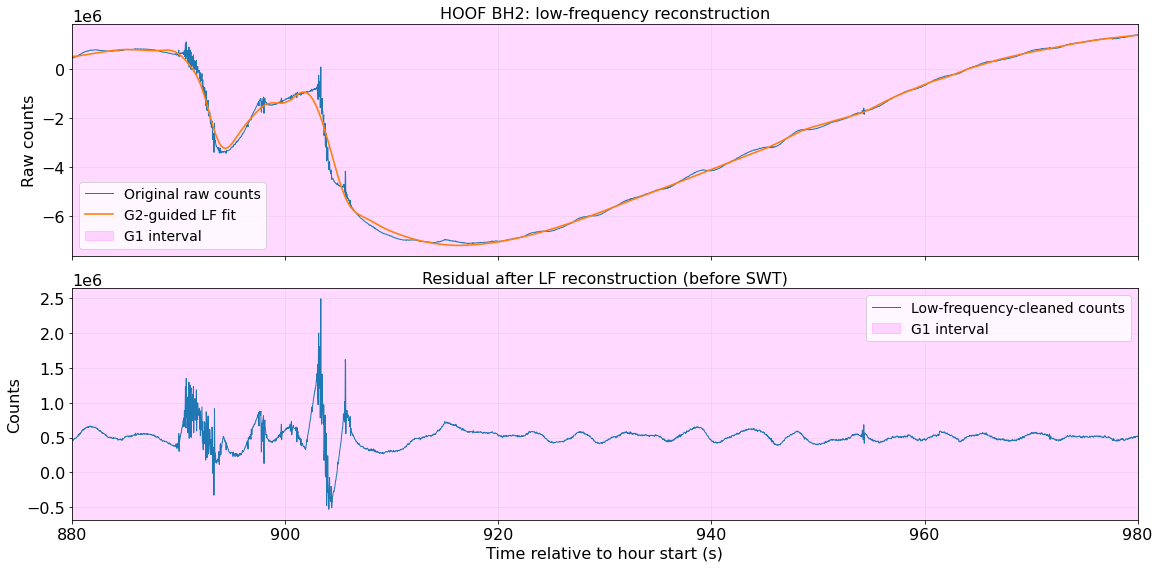

In [37]:
# ============================================================
# USER SETTINGS
# ============================================================

stnPlot = "HOOF"
compPlot = "BH2"          # Choose "BH1" or "BH2"

plotRange = (880, 980)  # Seconds relative to hourStartThis
# plotRange = (0, extractLen)  # Entire processed hour

# ============================================================
# SELECT STATION AND COMPONENT
# ============================================================

stnNo = deGlitchStns.index(stnPlot)

compNo = {"BH1": 0, "BH2": 1}[compPlot]
indNow = deGlitchInd[stnNo][compNo]

trRaw = streamAll[indNow][0]
trClean = streamAllLF[indNow][0]

fs = float(trRaw.stats.sampling_rate)

t = (np.arange(len(trRaw.data)) / fs + float(trRaw.stats.starttime - hourStartThis))
raw = np.asarray(trRaw.data, dtype=float)
clean = np.asarray(trClean.data, dtype=float)

# G2-guided physical fitting result
fit = g2FitsAll[stnNo].get(indNow)

if fit is not None:
    fitAccepted = fit.get("production_accepted", False)
    tFit = fit["fit_time"]
    fittedLF = fit["fitted_lowpass_signal"]

    print("Fit accepted:", fitAccepted)
    print("Merged onsets:", len(fit["onset_times_hour"]))
    print("Weighted VR:",
          fit["diagnostics"]["weighted_gain_vs_baseline_only"])
else:
    fitAccepted = False
    print("No G2-guided LF fit available for this component.")

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    2, 1,
    figsize=(16, 8),
    sharex=True
)

# ------------------------------------------------------------
# Original waveform + reconstructed LF fit
# ------------------------------------------------------------

ax[0].plot(t, raw,color="tab:blue",lw=1.0,label="Original raw counts")
if fit is not None:
    ax[0].plot(tFit, fittedLF,color="tab:orange",lw=1.6,ls="-" if fitAccepted else "--",
               label=("G2-guided LF fit"
               if fitAccepted else "G2-guided LF fit (not applied)"))
ax[0].set_ylabel("Raw counts")
ax[0].set_title(f"{stnPlot} {compPlot}: low-frequency reconstruction")
ax[0].grid(alpha=0.2)

# ------------------------------------------------------------
# Lower panel: LF-cleaned waveform
# ------------------------------------------------------------

ax[1].plot(t, clean,color="tab:blue",lw=1.0,label="Low-frequency-cleaned counts")
ax[1].set_ylabel("Counts")
ax[1].set_xlabel("Time relative to hour start (s)")
ax[1].set_title("Residual after LF reconstruction (before SWT)")
ax[1].grid(alpha=0.2)

# ------------------------------------------------------------
# G1 broad intervals: shared between both panels
# These indices are relative to hourStartThis - dataBuffB
# ------------------------------------------------------------

g1Intervals = eventsPassHorAll[stnNo]

for i, (startInd, endInd) in enumerate(g1Intervals):

    tStart = startInd / fs - dataBuffB
    tEnd = endInd / fs - dataBuffB

    for axis in ax:
        axis.axvspan(tStart, tEnd,color="magenta",alpha=0.15,label="G1 interval" if i == 0 else None)

# ------------------------------------------------------------
# Finish
# ------------------------------------------------------------

ax[1].set_xlim(*plotRange)

for axis in ax:
    axis.legend(loc="best")

    # Rescale Y to the displayed time interval
    oldDeGlitch.autoscaleAllLinesToVisibleX(axis)

plt.tight_layout()
plt.show()

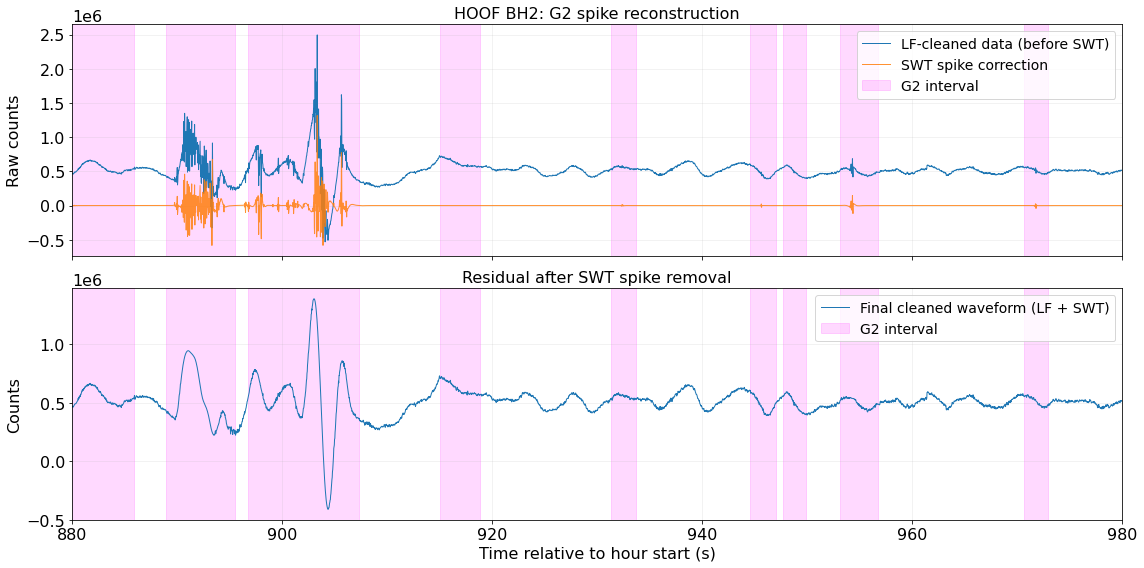

In [39]:
# ============================================================
# USER SETTINGS
# ============================================================

stnPlot = "HOOF"
compPlot = "BH2"               # "BH1", "BH2", or "BHZ"

plotRange = (880, 980)       # Seconds relative to hour start
# plotRange = (0, extractLen)  # Entire hour

# ============================================================
# SELECT STATION AND COMPONENT
# ============================================================

stnNo = deGlitchStns.index(stnPlot)

compNo = {"BH1": 0, "BH2": 1, "BHZ": 2}[compPlot]
indNow = deGlitchInd[stnNo][compNo]

# Input to SWT: after low-frequency reconstruction
trBefore = streamAllLF[indNow][0]

# Output of SWT: final cleaned waveform
trAfter = streamAllStage2[indNow][0]

fs = float(trBefore.stats.sampling_rate)

t = (
    np.arange(len(trBefore.data)) / fs
    + float(trBefore.stats.starttime - hourStartThis)
)

before = np.asarray(trBefore.data, dtype=float)
after = np.asarray(trAfter.data, dtype=float)

if (len(before) != len(after) or not np.isclose(float(trAfter.stats.sampling_rate), fs) or abs(float(
    trBefore.stats.starttime - trAfter.stats.starttime)) > 0.5 / fs):
    raise ValueError("Input and output SWT traces are not aligned.")

# Actual correction applied by SWT
spikeModel = before - after

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(2, 1,figsize=(16, 8),sharex=True)
# ------------------------------------------------------------
# Upper panel: SWT input and estimated spike correction
# ------------------------------------------------------------

ax[0].plot(t, before,color="tab:blue",lw=1.0,label="LF-cleaned data (before SWT)")
ax[0].plot(t, spikeModel,color="tab:orange",lw=1.0,alpha=0.85,label="SWT spike correction")
ax[0].set_ylabel("Raw counts")
ax[0].set_title(f"{stnPlot} {compPlot}: G2 spike reconstruction")
ax[0].grid(alpha=0.2)
# ------------------------------------------------------------
# Lower panel: Final cleaned waveform
# ------------------------------------------------------------

ax[1].plot(t, after,color="tab:blue",lw=1.0,label="Final cleaned waveform (LF + SWT)")
ax[1].set_ylabel("Counts")
ax[1].set_xlabel("Time relative to hour start (s)")
ax[1].set_title("Residual after SWT spike removal")
ax[1].grid(alpha=0.2)

# ------------------------------------------------------------
# Refined G2 intervals
# Indices are relative to hourStartThis - dataBuffB
# ------------------------------------------------------------

g2Intervals = refinedEventsHorAll[stnNo]

for i, (startInd, endInd) in enumerate(g2Intervals):

    tStart = startInd / fSamp - dataBuffB
    tEnd = endInd / fSamp - dataBuffB

    for axis in ax:axis.axvspan(tStart,tEnd,color="magenta",alpha=0.15,label="G2 interval"
                                if i == 0 else None)

# ------------------------------------------------------------
# Finish
# ------------------------------------------------------------

ax[1].set_xlim(*plotRange)
for axis in ax:
    axis.legend(loc="best")
    oldDeGlitch.autoscaleAllLinesToVisibleX(axis)

plt.tight_layout()
plt.show()

In [40]:
streamAll

[1 Trace(s) in Stream:
NL.HOOF.01.BH1 | 2026-08-13T11:56:00.000000Z - 2026-08-13T13:03:00.000000Z | 40.0 Hz, 160801 samples,
 1 Trace(s) in Stream:
NL.HOOF.01.BH2 | 2026-08-13T11:56:00.000000Z - 2026-08-13T13:03:00.000000Z | 40.0 Hz, 160801 samples,
 1 Trace(s) in Stream:
NL.HOOF.01.BHZ | 2026-08-13T11:56:00.000000Z - 2026-08-13T13:03:00.000000Z | 40.0 Hz, 160801 samples]

In [41]:
# print the number of events and data loss per hour
print('Number of events in HOOF in last hour = ' + str(totEventCountPerHourAll['HOOF'][0]))
print('Number of seconds lost in HOOF in last hour = ' + str(dataLossPerHourAll['HOOF'][0]))


Number of events in HOOF in last hour = 21
Number of seconds lost in HOOF in last hour = 110.7


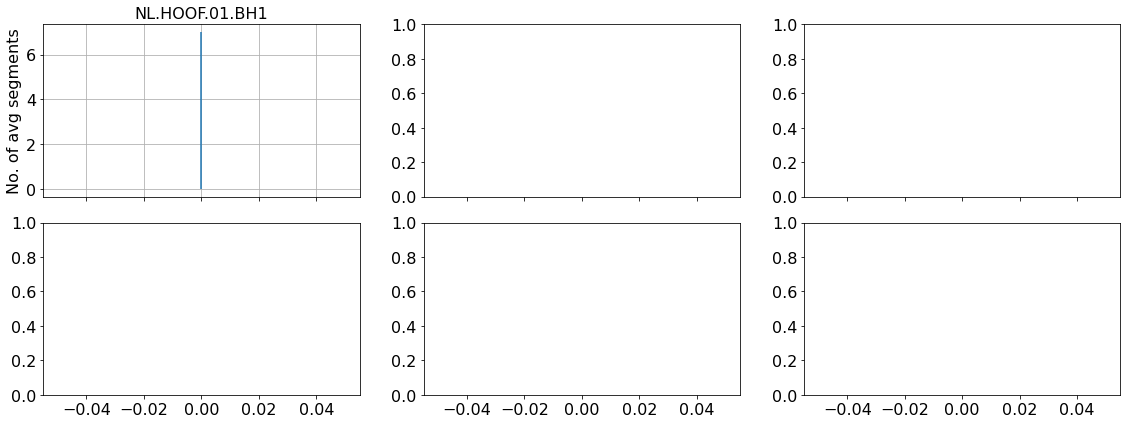

In [43]:
# run it in case of many days analysis
compPlot = [0,]
fig,ax = plt.subplots(2,3,figsize=(16,6),sharex=True)
nCleanMBAllArr = np.array(nCleanMBAll)
for i in range(0,len(compPlot)):
    tVec = np.arange(0,np.shape(nCleanMBAll)[0])/24
    
    y_data = nCleanMBAllArr[:, int(compPlot[i])].astype(float)

    # 2. Create a mask to filter out the nan values
    valid_mask = ~np.isnan(y_data)
    rNo = i//3; cNo = i%3
    # 3. Plot only the valid entries
    if(len(y_data[valid_mask])!=0):
        ax[rNo][cNo].stem(tVec[valid_mask], y_data[valid_mask], markerfmt=' ', basefmt='b-')
        
        ax[rNo,cNo].grid()
        ax[rNo,cNo].set_title(psdAllMB[compPlot[i]]["seed_id"])
        if(rNo==1):
            ax[rNo,cNo].set_xlabel('Time (days)')
        if(cNo==0):
            ax[rNo,cNo].set_ylabel('No. of avg segments')

plt.tight_layout()
plt.show()

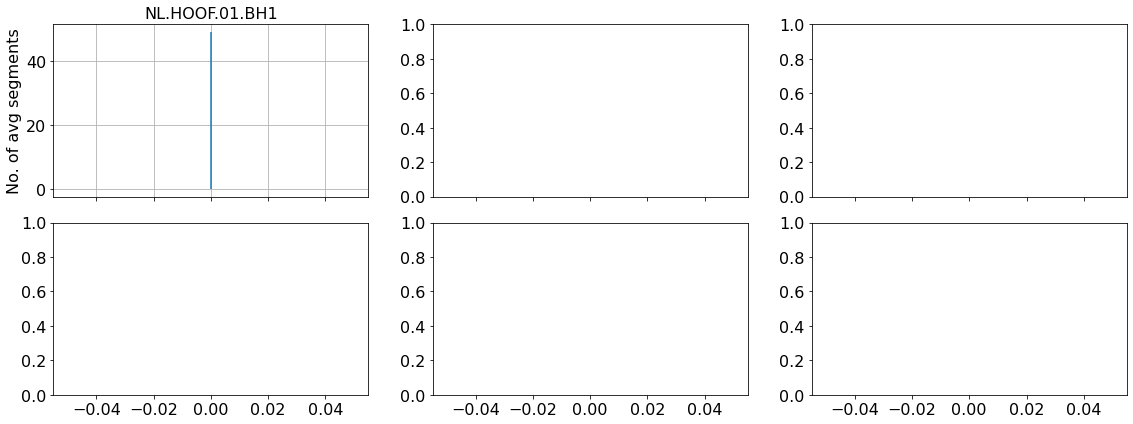

In [44]:
# run it in case of many days analysis
compPlot = [0,]
fig,ax = plt.subplots(2,3,figsize=(16,6),sharex=True)
nClean120AllArr = np.array(nClean120All)
for i in range(0,len(compPlot)):
    tVec = np.arange(0,np.shape(nClean120All)[0])/24
    
    y_data = nClean120AllArr[:, int(compPlot[i])].astype(float)

    # 2. Create a mask to filter out the nan values
    valid_mask = ~np.isnan(y_data)
    rNo = i//3; cNo = i%3
    # 3. Plot only the valid entries
    if(len(y_data[valid_mask])!=0):
        ax[rNo][cNo].stem(tVec[valid_mask], y_data[valid_mask], markerfmt=' ', basefmt='b-')
        
        ax[rNo,cNo].grid()
        ax[rNo,cNo].set_title(psdAllMB[compPlot[i]]["seed_id"])
        if(rNo==1):
            ax[rNo,cNo].set_xlabel('Time (days)')
        if(cNo==0):
            ax[rNo,cNo].set_ylabel('No. of avg segments')

plt.tight_layout()
plt.show()

In [45]:
print(dateEndUse)

2026-08-13T13:00:00.000000Z


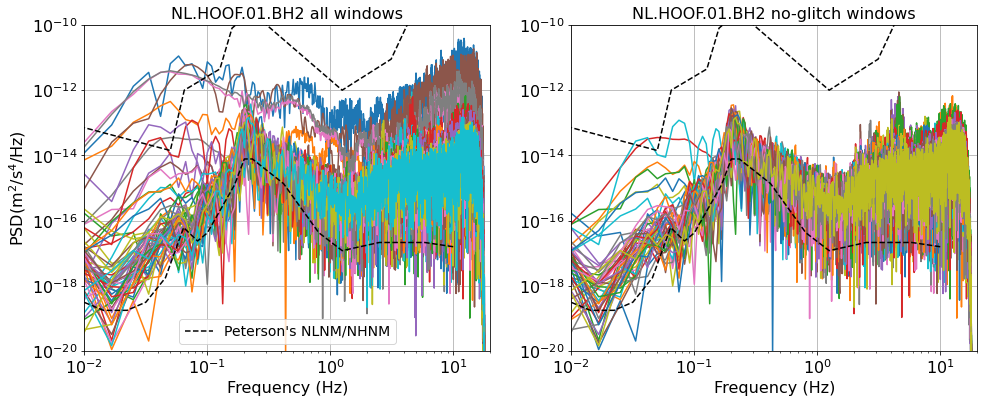

In [46]:
fig,ax = plt.subplots(1,2,figsize=(16,6))
compPlot = 1 # corresp[onds to Hoof BH1, underground
petModel = loadmat('PETERSON.mat')
for i in range(0,len(psdAll[compPlot]['psd'][:,0])):
    ax[0].loglog(psdAll[compPlot]['frequencies'],psdAll[compPlot]['psd'][i,:])

#ax[0].loglog(psdAllMB[compPlot]['frequencies'],psdAllMB[compPlot]['psd'][0,:],'m-',linewidth=2.0)
ax[0].loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax[0].loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')
ax[0].set_xlim(0.01,20)
ax[0].set_ylim(10**-20,10**-10)
ax[0].legend()
ax[0].set_ylabel(r'$\mathrm{PSD}\mathrm{(m}^2\mathrm{/s}^4\mathrm{/Hz})$')
ax[0].set_xlabel('Frequency (Hz)')
ax[0].set_title(psdAll[compPlot]["seed_id"] + ' all windows' )
ax[0].grid()
# get the other plot
for i in range(0,len(psdAllDeGlitch[compPlot]['psd'][:,0])):
    ax[1].loglog(psdAllDeGlitch[compPlot]['frequencies'],psdAllDeGlitch[compPlot]['psd'][i,:])
#ax[1].loglog(psdAllMBDeGlitch[compPlot]['frequencies'],psdAllMBDeGlitch[compPlot]['psd'][0,:],'m-',linewidth=2.0)
ax[1].loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax[1].loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')

ax[1].set_xlim(0.01,20)
ax[1].set_ylim(10**-20,10**-10)
ax[1].set_xlabel('Frequency (Hz)')
ax[1].set_title(psdAll[compPlot]["seed_id"] + ' no-glitch windows' )
ax[1].grid()

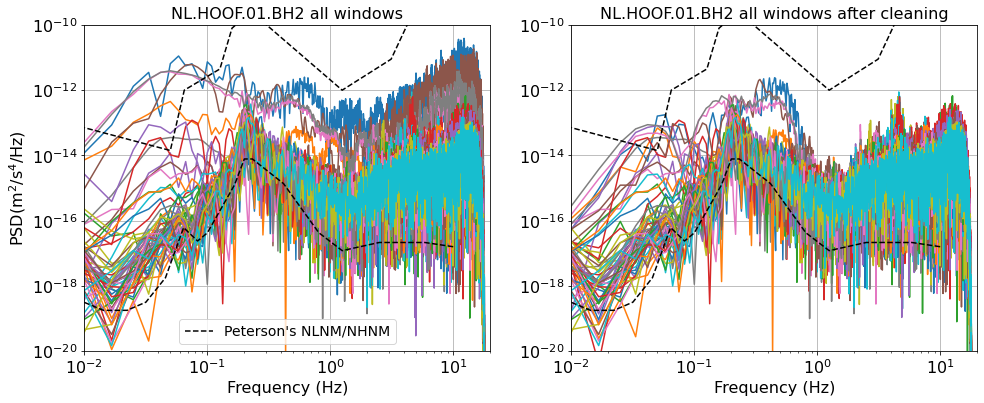

In [47]:
fig,ax = plt.subplots(1,2,figsize=(16,6))
compPlot = 1 # corresp[onds to Hoof BH1, underground
petModel = loadmat('PETERSON.mat')
for i in range(0,len(psdAll[compPlot]['psd'][:,0])):
    ax[0].loglog(psdAll[compPlot]['frequencies'],psdAll[compPlot]['psd'][i,:])

#ax[0].loglog(psdAllMB[compPlot]['frequencies'],psdAllMB[compPlot]['psd'][0,:],'m-',linewidth=2.0)
ax[0].loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax[0].loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')
ax[0].set_xlim(0.01,20)
ax[0].set_ylim(10**-20,10**-10)
ax[0].legend()
ax[0].set_ylabel(r'$\mathrm{PSD}\mathrm{(m}^2\mathrm{/s}^4\mathrm{/Hz})$')
ax[0].set_xlabel('Frequency (Hz)')
ax[0].set_title(psdAll[compPlot]["seed_id"] + ' all windows' )
ax[0].grid()
# get the other plot
for i in range(0,len(psdAllWaveletClean[compPlot]['psd'][:,0])):
    ax[1].loglog(psdAllWaveletClean[compPlot]['frequencies'],psdAllWaveletClean[compPlot]['psd'][i,:])
#ax[1].loglog(psdAllMBDeGlitch[compPlot]['frequencies'],psdAllMBDeGlitch[compPlot]['psd'][0,:],'m-',linewidth=2.0)
ax[1].loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax[1].loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')

ax[1].set_xlim(0.01,20)
ax[1].set_ylim(10**-20,10**-10)
ax[1].set_xlabel('Frequency (Hz)')
ax[1].set_title(psdAll[compPlot]["seed_id"] + ' all windows after cleaning' )
ax[1].grid()

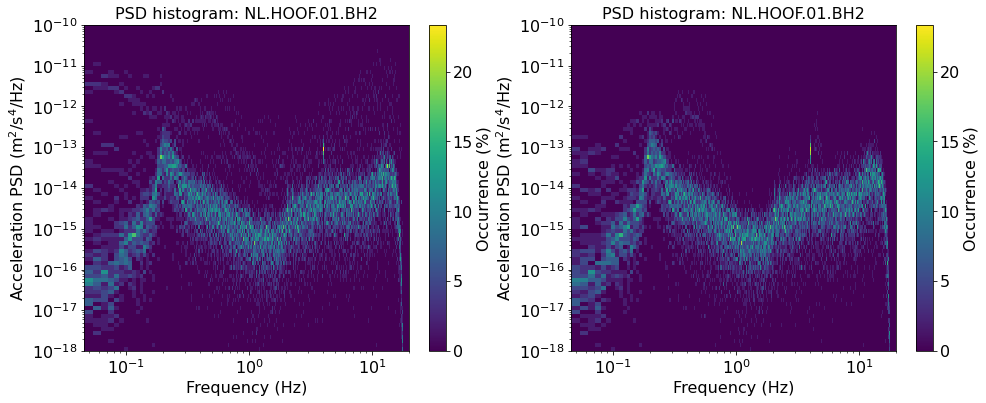

In [48]:
# check the histograms with and without glitches for the 120 s window
compPlot = 1
seedID = None
fig,ax = plt.subplots(1,2,figsize=(16,6))
if psdAll[compPlot] is not None:
    seedID = psdAll[compPlot]["seed_id"]

psdEst.plotPSDHistogram(histAll=histAll,channelNo=compPlot,freqHist=freqEdges,psdEdges=psdEdges,ax=ax[0],seedID=seedID,normalize=True,)
ax[0].set_ylim(10**-18,10**-10)

psdEst.plotPSDHistogram(histAll=histAllDeGlitchRec,channelNo=compPlot,freqHist=freqEdges,psdEdges=psdEdges,ax=ax[1],seedID=seedID,normalize=True,)
ax[1].set_ylim(10**-18,10**-10)
plt.show()

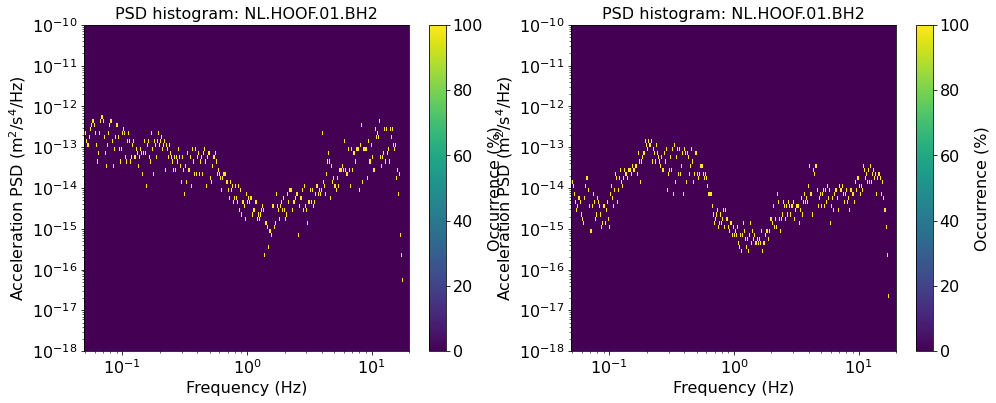

In [49]:
# check the histograms with and without glitches for Mcnamara Buland approach, not really meaningful
# only one entry
compPlot = 1
seedID = None
fig,ax = plt.subplots(1,2,figsize=(16,6))
if psdAll[compPlot] is not None:
    seedID = psdAll[compPlot]["seed_id"]

psdEst.plotPSDHistogram(histAll=histAllMB,channelNo=compPlot,freqHist=freqEdgesMB,psdEdges=psdEdgesMB,ax=ax[0],seedID=seedID,normalize=True,)
ax[0].set_ylim(10**-18,10**-10)

psdEst.plotPSDHistogram(histAll=histAllMBDeGlitchRec,channelNo=compPlot,freqHist=freqEdgesMB,psdEdges=psdEdgesMB,ax=ax[1],seedID=seedID,normalize=True,)
ax[1].set_ylim(10**-18,10**-10)
plt.show()

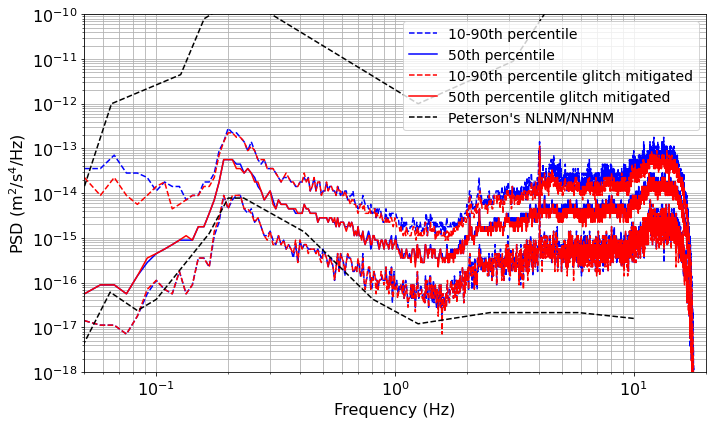

In [50]:
# 120 s approach of raw without glitch mitigation and with glitch mitigation
compPlot = 1
percentilePSD = psdEst.percentilesFromHistogram(hist=histAll[compPlot],psdEdges=psdEdges,percentiles=(10, 50, 90),)
percentilePSDDeGlitch = psdEst.percentilesFromHistogram(hist=histAllDeGlitchRec[compPlot],psdEdges=psdEdges,percentiles=(10, 50, 90),)

psdP10 = percentilePSD[0];psdP50 = percentilePSD[1];psdP90 = percentilePSD[2]
psdP10DeGlitch = percentilePSDDeGlitch[0];psdP50DeGlitch = percentilePSDDeGlitch[1];psdP90DeGlitch = percentilePSDDeGlitch[2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(freqHist, psdP10,'b--',label="10-90th percentile")
ax.loglog(freqHist, psdP50,'b', label="50th percentile")
ax.loglog(freqHist, psdP90,'b--')

ax.loglog(freqHist, psdP10DeGlitch,'r--',label="10-90th percentile glitch mitigated")
ax.loglog(freqHist, psdP50DeGlitch,'r', label="50th percentile glitch mitigated")
ax.loglog(freqHist, psdP90DeGlitch,'r--')

petModel = loadmat('PETERSON.mat')
ax.loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax.loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')

ax.set_xlim(0.05, 20.0)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"PSD ($\mathrm{m^2/s^4/Hz}$)")
ax.legend()
ax.grid(True, which="both")
ax.set_ylim(10**-18, 10**-10)
fig.tight_layout()
plt.show()

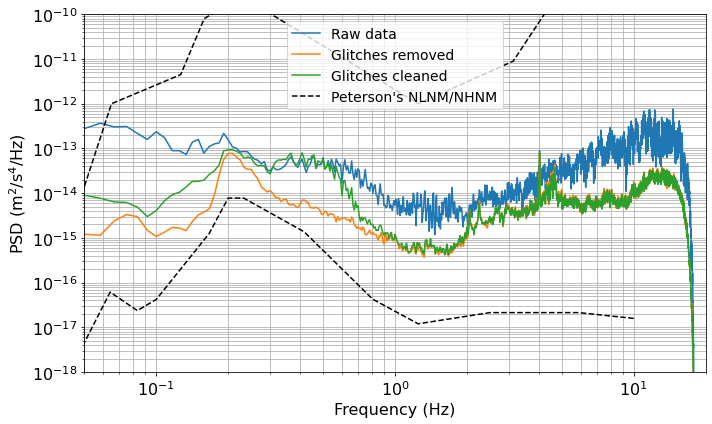

In [51]:
# also worth plotting the averages with raw without glitch mitigation, with glitch mitigation, and 
# with window removal
# so three cases
# plot may be BH1
compPlot = 1
fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(psdAllAvg[compPlot]['frequencies'],psdAllAvg[compPlot]['psd'][0,:],label='Raw data')
ax.loglog(psdAllDeGlitchAvg[compPlot]['frequencies'],psdAllDeGlitchAvg[compPlot]['psd'][0,:],label='Glitches removed')
ax.loglog(psdAllWaveletCleanAvg[compPlot]['frequencies'],psdAllWaveletCleanAvg[compPlot]['psd'][0,:],label='Glitches cleaned')

petModel = loadmat('PETERSON.mat')
ax.loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax.loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')

ax.set_xlim(0.05, 20.0)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"PSD ($\mathrm{m^2/s^4/Hz}$)")
ax.legend()
ax.grid(True, which="both")
ax.set_ylim(10**-18, 10**-10)
fig.tight_layout()
plt.show()

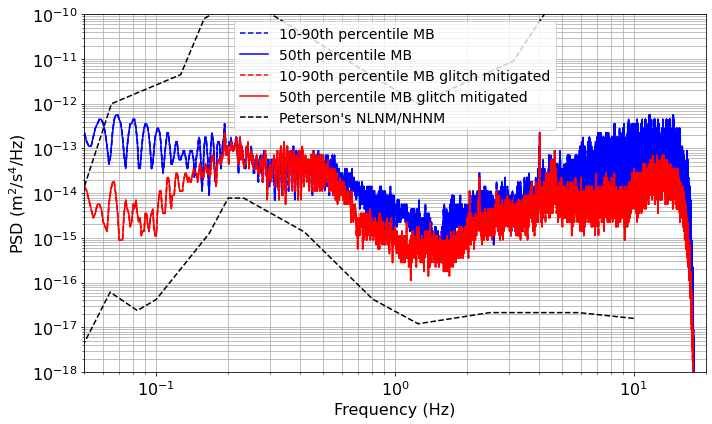

In [53]:
# McNamara Buland approach with glitch mitigation and without
compPlot = 1
percentilePSDMB = psdEst.percentilesFromHistogram(hist=histAllMB[compPlot],psdEdges=psdEdgesMB,percentiles=(10, 50, 90),)
percentilePSDMBDeGlitch = psdEst.percentilesFromHistogram(hist=histAllMBDeGlitchRec[compPlot],psdEdges=psdEdgesMB,percentiles=(10, 50, 90),)

psdP10MB = percentilePSDMB[0];psdP50MB = percentilePSDMB[1];psdP90MB = percentilePSDMB[2]
psdP10MBDeGlitch = percentilePSDMBDeGlitch[0];psdP50MBDeGlitch = percentilePSDMBDeGlitch[1];psdP90MBDeGlitch = percentilePSDMBDeGlitch[2]

fig, ax = plt.subplots(figsize=(10, 6))


ax.loglog(freqHistMB, psdP10MB,'b--',label="10-90th percentile MB")
ax.loglog(freqHistMB, psdP50MB,'b', label="50th percentile MB")
ax.loglog(freqHistMB, psdP90MB,'b--')

ax.loglog(freqHistMB, psdP10MBDeGlitch,'r--',label="10-90th percentile MB glitch mitigated")
ax.loglog(freqHistMB, psdP50MBDeGlitch,'r', label="50th percentile MB glitch mitigated")
ax.loglog(freqHistMB, psdP90MBDeGlitch,'r--')

petModel = loadmat('PETERSON.mat')
ax.loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax.loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')

ax.set_xlim(0.05, 20.0)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"PSD ($\mathrm{m^2/s^4/Hz}$)")
ax.legend()
ax.grid(True, which="both")
ax.set_ylim(10**-18, 10**-10)
fig.tight_layout()
plt.show()

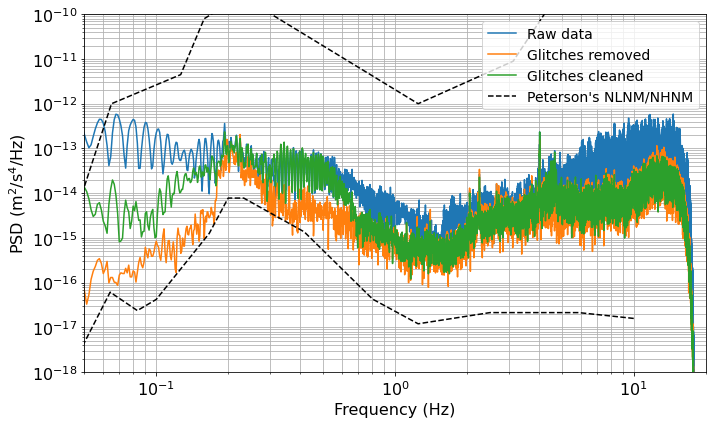

In [54]:
# also worth plotting the averages with raw without glitch mitigation, with glitch mitigation, and 
# with window removal for MB approach
# so three cases
# plot may be BH1
compPlot = 1
fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(psdAllMB[compPlot]['frequencies'],psdAllMB[compPlot]['psd'][0,:],label='Raw data')
ax.loglog(psdAllMBDeGlitch[compPlot]['frequencies'],psdAllMBDeGlitch[compPlot]['psd'][0,:],label='Glitches removed')
ax.loglog(psdAllMBWaveletClean[compPlot]['frequencies'],psdAllMBWaveletClean[compPlot]['psd'][0,:],label='Glitches cleaned')

petModel = loadmat('PETERSON.mat')
ax.loglog(petModel['fh'],petModel['hnm']**2*(2*np.pi*petModel['fh'])**2,'k--',label = 'Peterson\'s NLNM/NHNM')
ax.loglog(petModel['fl'],petModel['lnm']**2*(2*np.pi*petModel['fl'])**2,'k--')

ax.set_xlim(0.05, 20.0)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"PSD ($\mathrm{m^2/s^4/Hz}$)")
ax.legend()
ax.grid(True, which="both")
ax.set_ylim(10**-18, 10**-10)
fig.tight_layout()
plt.show()